<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


First 5 rows:
     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  

Dataset Shape: (5572, 2)

Training Data: (4457,)
Testing Data: (1115,)

TF-IDF Training Shape: (4457, 8082)

Accuracy: 96.23 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.72      0.84       149

    accuracy                           0.96      1115
   macro avg       0.

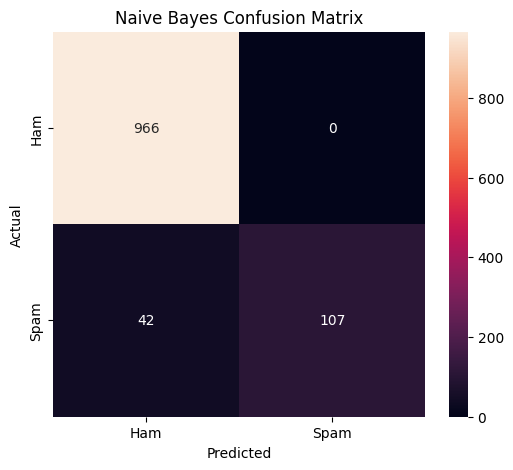


New Message:
Congratulations! You have won a free prize
Prediction: spam


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

df = pd.read_csv('/content/drive/MyDrive/ML/spam.csv',
                 encoding='latin-1')

print("First 5 rows:")
print(df.head())

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

df = df.dropna()

print("\nDataset Shape:", df.shape)

df['message'] = df['message'].str.lower()

df['message'] = df['message'].str.replace(
    r'[^a-zA-Z0-9\s]', '',
    regex=True
)

X = df['message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

vectorizer = TfidfVectorizer(
    stop_words='english'
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print("\nTF-IDF Training Shape:",
      X_train_tfidf.shape)

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['ham', 'spam']
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")

plt.show()

new_message = [
    "Congratulations! You have won a free prize"
]

new_message_tfidf = vectorizer.transform(new_message)

prediction = model.predict(new_message_tfidf)

print("\nNew Message:")
print(new_message[0])

print("Prediction:", prediction[0])
